In [36]:
import pandas as pd 
import numpy as np 
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix , recall_score , precision_score
from sklearn.preprocessing import StandardScaler


In [8]:
data= pd.read_csv("diabetes.csv")
data.head(5)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,Pedigree,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [10]:
data.isnull().sum() 

Pregnancies      0
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
Pedigree         0
Age              0
Outcome          0
dtype: int64

In [22]:
x= data.drop(["Outcome"] , axis = 1)
y = data["Outcome"]

y.head(), x.head()

(0    1
 1    0
 2    1
 3    0
 4    1
 Name: Outcome, dtype: int64,
    Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
 0            6      148             72             35        0  33.6   
 1            1       85             66             29        0  26.6   
 2            8      183             64              0        0  23.3   
 3            1       89             66             23       94  28.1   
 4            0      137             40             35      168  43.1   
 
    Pedigree  Age  
 0     0.627   50  
 1     0.351   31  
 2     0.672   32  
 3     0.167   21  
 4     2.288   33  )

In [24]:
x_train , x_test , y_train , y_test = train_test_split(x, y , test_size=0.2 , random_state=42 )

In [26]:
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [28]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(x_train , y_train )
knn_predect = knn.predict(x_test)


In [32]:
conf_mat = confusion_matrix(knn_predect , y_test )
accuracy = accuracy_score(knn_predect , y_test)
error = 1-accuracy 
precesion = precision_score(knn_predect , y_test)
recall = recall_score(knn_predect , y_test)

In [34]:
conf_mat ,accuracy,error,precesion,recall 

(array([[79, 27],
        [20, 28]], dtype=int64),
 0.6948051948051948,
 0.30519480519480524,
 0.509090909090909,
 0.5833333333333334)

<Axes: >

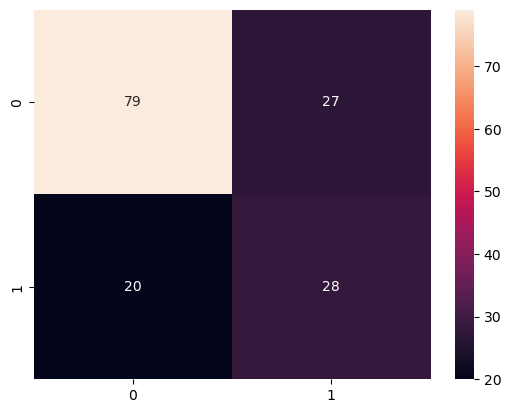

In [52]:
sns.heatmap(conf_mat, annot= True )

tp fn 
fp tn 

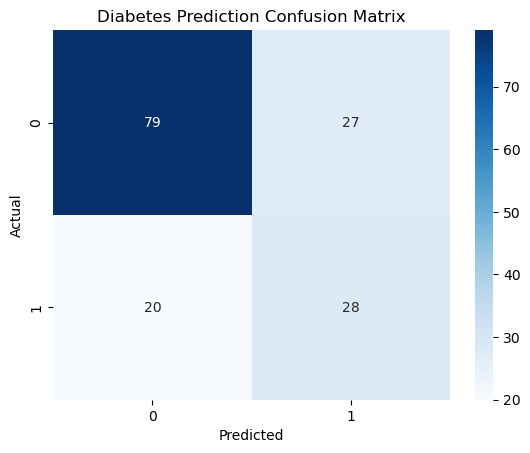

In [48]:
import matplotlib.pyplot as plt
sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues')

plt.title("Diabetes Prediction Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()